## Definición del Problema

In [1]:
# PIPELINE DE RAZONAMIENTO, BUSQUEDA Y RESULTADOS
# Caso: El Sueño en los Primeros Meses de Vida

problema = {
    "nombre": "Analisis del sueno neonatal",
    "objetivo": (
        "Encontrar una ruta valida desde la definicion "
        "del problema hasta un modelo predictivo evaluado."
    ),
    "estado_inicial": "S0",
    "estado_objetivo": "Sg"
}

print("PROBLEMA:", problema["nombre"])
print("Objetivo:", problema["objetivo"])
print("Estado inicial:", problema["estado_inicial"])
print("Estado objetivo:", problema["estado_objetivo"])

PROBLEMA: Analisis del sueno neonatal
Objetivo: Encontrar una ruta valida desde la definicion del problema hasta un modelo predictivo evaluado.
Estado inicial: S0
Estado objetivo: Sg


##Definición del Espacio de Estados

In [2]:
estados = {
    "S0": "Problema definido",
    "S1": "Datos recopilados",
    "S2": "Datos validados",
    "S3": "Datos preprocesados",
    "S4": "Variables seleccionadas",
    "S5": "Datos divididos",
    "S6": "Modelo entrenado",
    "S7": "Modelo evaluado",
    "Sg": "Modelo aceptado y documentado"
}

operadores = {
    "S0": [("O1", "S1", "Recopilar datos")],
    "S1": [("O2", "S2", "Validar datos")],
    "S2": [("O3", "S3", "Preprocesar datos")],
    "S3": [("O4", "S4", "Seleccionar variables")],
    "S4": [("O5", "S5", "Dividir datos")],
    "S5": [("O6", "S6", "Entrenar modelo")],
    "S6": [("O7", "S7", "Evaluar modelo")],
    "S7": [
        ("O8", "Sg", "Aceptar y documentar"),
        ("O9", "S3", "Ajustar el proceso")
    ],
    "Sg": []
}

print("ESTADOS DEL PROBLEMA")
for codigo, descripcion in estados.items():
    print(f"{codigo}: {descripcion}")

ESTADOS DEL PROBLEMA
S0: Problema definido
S1: Datos recopilados
S2: Datos validados
S3: Datos preprocesados
S4: Variables seleccionadas
S5: Datos divididos
S6: Modelo entrenado
S7: Modelo evaluado
Sg: Modelo aceptado y documentado


##Restricciones del Proceso

In [3]:
restricciones = {
    "datos_disponibles": True,
    "datos_validados": True,
    "variable_objetivo_valida": True,
    "sin_fuga_de_datos": True,
    "privacidad_protegida": True,
    "modelo_evaluable": True
}

print("RESTRICCIONES DEL PIPELINE")

for nombre, cumple in restricciones.items():
    print(f"{nombre}: {'Cumple' if cumple else 'No cumple'}")

RESTRICCIONES DEL PIPELINE
datos_disponibles: Cumple
datos_validados: Cumple
variable_objetivo_valida: Cumple
sin_fuga_de_datos: Cumple
privacidad_protegida: Cumple
modelo_evaluable: Cumple


Los valores anteriores representan condiciones de una simulación del flujo. No prueban que exista un conjunto real de datos neonatales ni que un modelo haya sido entrenado.

##Implementación de Búsqueda en Anchura (BFS)

In [4]:
from collections import deque

def busqueda_bfs(estado_inicial, estado_objetivo, grafo):
    cola = deque([(estado_inicial, [estado_inicial])])
    visitados = set()

    while cola:
        estado_actual, camino = cola.popleft()

        if estado_actual == estado_objetivo:
            return camino

        if estado_actual in visitados:
            continue

        visitados.add(estado_actual)

        for operador, siguiente, accion in grafo.get(
            estado_actual, []
        ):
            if siguiente not in visitados:
                cola.append((siguiente, camino + [siguiente]))

    return None


ruta = busqueda_bfs("S0", "Sg", operadores)

if ruta:
    print("Ruta encontrada:")
    for i, codigo in enumerate(ruta):
        print(f"{i + 1}. {codigo} - {estados[codigo]}")
else:
    print("No se encontro una ruta al objetivo.")

Ruta encontrada:
1. S0 - Problema definido
2. S1 - Datos recopilados
3. S2 - Datos validados
4. S3 - Datos preprocesados
5. S4 - Variables seleccionadas
6. S5 - Datos divididos
7. S6 - Modelo entrenado
8. S7 - Modelo evaluado
9. Sg - Modelo aceptado y documentado


##Exploración de Operadores

In [5]:
print("EXPLORACION DE TRANSICIONES")

for estado, transiciones in operadores.items():
    for operador, destino, accion in transiciones:
        print(
            f"{estado} --{operador}: {accion}--> {destino}"
        )

EXPLORACION DE TRANSICIONES
S0 --O1: Recopilar datos--> S1
S1 --O2: Validar datos--> S2
S2 --O3: Preprocesar datos--> S3
S3 --O4: Seleccionar variables--> S4
S4 --O5: Dividir datos--> S5
S5 --O6: Entrenar modelo--> S6
S6 --O7: Evaluar modelo--> S7
S7 --O8: Aceptar y documentar--> Sg
S7 --O9: Ajustar el proceso--> S3


##Verificación del resultado

In [6]:
def verificar_restricciones(restricciones):
    return all(restricciones.values())


if ruta and verificar_restricciones(restricciones):
    resultado = "Ruta encontrada y restricciones satisfechas."
else:
    resultado = (
        "No se puede aceptar la solucion: "
        "faltan condiciones o no existe una ruta valida."
    )

print("RESULTADO DEL PIPELINE")
print(resultado)

RESULTADO DEL PIPELINE
Ruta encontrada y restricciones satisfechas.


## Representación Visual de la Ruta

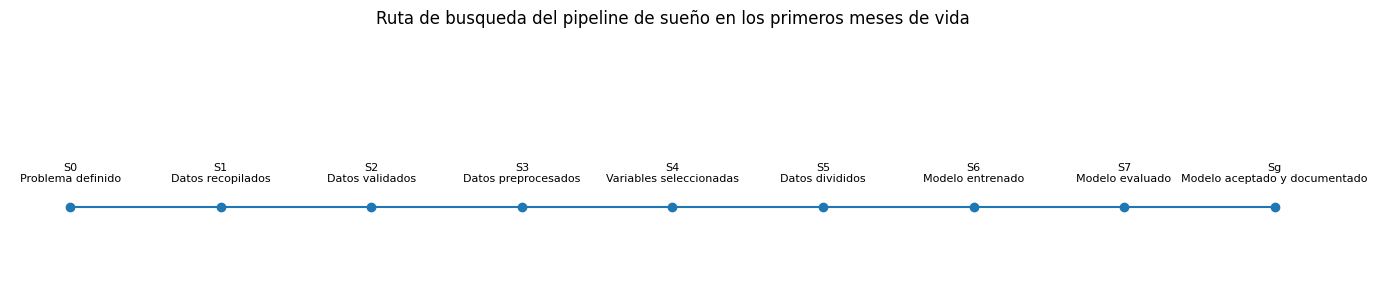

In [8]:
import matplotlib.pyplot as plt

if ruta:
    fig, ax = plt.subplots(figsize=(14, 3))

    posiciones = list(range(len(ruta)))
    ax.plot(posiciones, [0] * len(ruta), marker="o")

    for x, codigo in zip(posiciones, ruta):
        ax.annotate(
            f"{codigo}\n{estados[codigo]}",
            (x, 0),
            xytext=(0, 18),
            textcoords="offset points",
            ha="center",
            fontsize=8
        )

    ax.set_title("Ruta de busqueda del pipeline de sueño en los primeros meses de vida")
    ax.set_xlim(-0.4, len(ruta) - 0.6)
    ax.set_ylim(-0.5, 1.2)
    ax.axis("off")
    plt.tight_layout()
    plt.show()